## Gibbs Phenomeno - Problem 3 b and c

#### Plot f together with S_N for N = 5, 20, 100.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

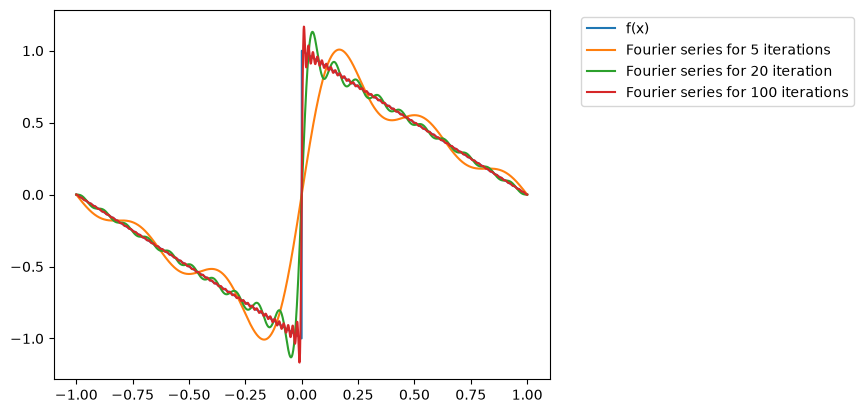

In [2]:


def f(x): # on [0, 1]
    return 1 - x

def f_odd_ext(x): # on [-1, 0]
    return -f(-x)

def f_piecewise(x):
    return np.where(x >= 0, f(x), f_odd_ext(x)) # if x >0 we use func on [0, 1] otherwise odd extension


def vectorized_series(x, N):
    terms = [2 / (n * np.pi) * np.sin(n * np.pi * x) for n in range(1, N + 1)]
    return np.sum(terms, axis=0) # must sum over axis = 0, one number for each point across x-axis


x = np.linspace(-1, 1, 2000)
plt.figure()
plt.plot(x, f_piecewise(x), label="f(x)")
plt.plot(x, vectorized_series(x, 5), label="Fourier series for 5 iterations")
plt.plot(x, vectorized_series(x, 20), label="Fourier series for 20 iteration")
plt.plot(x, vectorized_series(x, 100), label="Fourier series for 100 iterations")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

#### Compute $\varepsilon_{1000}$

In [3]:
x = np.linspace(-1, 1, 100000)
eps_1000 = np.max(np.abs(vectorized_series(x, 1000) - f_piecewise(x)))
print(f"EPS_100: {eps_1000:2f}")
print(f"Jump error: {(1/2 * eps_1000):2f}")

EPS_100: 0.979991
Jump error: 0.489995


#### Discussion

- $\varepsilon_N$ does not reach 0 as N grows, it reaches 1. This is because at the jump $x = 0$, $S_N(0) = 0$, while $f(0)=1$, therefore the difference at that point is 1 and the maximum error is 1
- Expressing $\varepsilon_{1000} \approx 1$ as a percentage of jump 2 gives $\frac{1}{2} \cdot \varepsilon_{1000} \approx 50 \% $
- The Gibbs phenomenon is shown from this since near the jump discontinuity at $x = 0$, the Fourier series produces persistent overshoot oscillations. While these oscillations compress narrower and closer to the jump as $N$ increases, their amplitude does not diminish, preventing uniform convergence on $[-1, 1]$